### Install required packages
This cell installs the libraries needed for data loading, plotting, and tokenizer training.

In [ ]:
%pip install pandas numpy matplotlib seaborn tqdm tokenizers

### Import libraries
This cell loads the Python packages used throughout the notebook and sets a fixed random seed for reproducibility.

In [5]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from datasets import load_dataset
from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece
from tokenizers.trainers import BpeTrainer, WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import NFKC
from tokenizers.processors import TemplateProcessing

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

### Run the next analysis step
This cell performs the next stage of the tokenizer experiment and helps interpret the model behavior.

### Install required packages
This cell installs the libraries needed for data loading, plotting, and tokenizer training.

In [ ]:
%pip install datasets

### Configure the language
This block defines the target language and the dataset paths used to fetch the correct corpus.

In [6]:
LANGUAGE = "sanskrit"

LANGUAGE_CONFIG = {
    "assamese": ("asm_Beng", "data/as.txt"),
    "bengali": ("ben_Beng", "data/bn.txt"),
    "bodo": ("brx_Deva", "data/bd.txt"),
    "dogri": ("doi_Deva", "data/dg.txt"),
    "goan_konkani": ("gom_Deva", "data/gom.txt"),
    "gujarati": ("guj_Gujr", "data/gu.txt"),
    "hindi": ("hin_Deva", "data/hi-*.txt"),
    "kannada": ("kan_Knda", "data/kn.txt"),
    "kashmiri": ("kas_Arab", "data/ks.txt"),
    "maithili": ("mai_Deva", "data/mai.txt"),
    "malayalam": ("mal_Mlym", "data/ml.txt"),
    "marathi": ("mar_Deva", "data/mr.txt"),
    "manipuri": ("mni_Mtei", "data/mni.txt"),
    "nepali": ("npi_Deva", "data/ne.txt"),
    "odia": ("ory_Orya", "data/or.txt"),
    "punjabi": ("pan_Guru", "data/pa.txt"),
    "sanskrit": ("san_Deva", "data/sa.txt"),
    "sindhi": ("snd_Deva", "data/sd.txt"),
    "tamil": ("tam_Taml", "data/ta.txt"),
    "telugu": ("tel_Telu", "data/te.txt"),
    "urdu": ("urd_Arab", "data/ur.txt"),
}

CONFIG, DATA_DIR = LANGUAGE_CONFIG[LANGUAGE]

print("Language:", LANGUAGE)
print("Config:", CONFIG)
print("Data directory:", DATA_DIR)

Language: sanskrit
Config: san_Deva
Data directory: data/sa.txt


### Install required packages
This cell installs the libraries needed for data loading, plotting, and tokenizer training.

In [ ]:
%pip install -U datasets huggingface_hub

### Load the corpus
This cell loads the IndicCorp dataset for the selected language and prepares it for text processing.

In [34]:
dataset = load_dataset(
    "ai4bharat/IndicCorpV2",
    "indiccorp_v2",
    split="hin_Deva",
    streaming=True
)

### Sentence splitting helper
This function normalizes whitespace and splits paragraphs into clean sentence candidates for analysis.

In [35]:
def sentence_tokenize(text):
    if not isinstance(text, str):
        return []

    text = re.sub(r"\s+", " ", text).strip()

    sentences = re.split(
        r"(?<=[।!?])\s+|(?<=[.!?])\s+",
        text
    )

    return [
        s.strip()
        for s in sentences
        if len(s.strip()) >= 3
    ]

### Load the corpus
This cell loads the IndicCorp dataset for the selected language and prepares it for text processing.

In [38]:
TARGET_SENTENCES = 1_002_000

sentences = []

dataset = load_dataset(
    "ai4bharat/IndicCorpV2",
    "indiccorp_v2",
    split="hin_Deva",
    streaming=True
)

for example in tqdm(dataset, desc="Streaming IndicCorpV2"):

    paragraph = example["text"]

    new_sentences = sentence_tokenize(paragraph)

    sentences.extend(new_sentences)

    if len(sentences) >= TARGET_SENTENCES:
        break

print("Total sentences collected:", len(sentences))

Streaming IndicCorpV2: 613464it [01:12, 8469.78it/s] 

Total sentences collected: 1002002


### Inspect corpus samples
This block prints collection statistics and previews the first sentences in the dataset.

In [39]:
print("Total sentences:", len(sentences))

print("\nFirst 5 sentences:\n")

for i, sentence in enumerate(sentences[:5]):
    print(f"{i+1}. {sentence}")

Total sentences: 1002002

First 5 sentences:

1. लोगों को बिलों संबंधी सुविधा देना ही उनका काम
2. इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थी, जब पूर्व उपप्रधानमंत्री देवीलाल ने अपने पुत्र ओमप्रकाश चौटाला को अपना राजनीतिक उत्तराधिकारी घोषित किया था।
3. हालांकि तब पार्टी पर देवीलाल की मजबूत पकड़ के चलते पार्टी टूटने से बच गई थी।
4. 1989 में देवीलाल केन्द्र की राजनीति में सक्रिय हो गए थे और उनके उपप्रधानमंत्री बनने के पश्चात् उनके तीन बेटों जगदीश सिंह, रणजीत सिंह और ओमप्रकाश चौटाला में से रणजीत और ओमप्रकाश के बीच हरियाणा में उनकी राजनीतिक विरासत को लेकर जंग शुरू हो गई थी।
5. उन परिस्थितियों में देवीलाल ने कड़ा निर्णय लेते हुए पार्टी की बागडोर ओमप्रकाश चौटाला के हवाले कर दी थी, जिसके बाद रणजीत की बगावत का असर पार्टी, संगठन और उनकी सरकार पर भी पड़ा था।


### Check for empty entries
This cell counts blank strings so the corpus can be cleaned before training.

In [40]:
empty_sentences = sum(
    1 for s in sentences
    if not s.strip()
)

print("Empty sentences:", empty_sentences)

Empty sentences: 0


### Create the analysis table
This block builds a dataframe of sentences and adds character and word-length features for analysis.

In [41]:
df = pd.DataFrame({
    "sentence": sentences
})

df["length_chars"] = df["sentence"].apply(len)

df["length_words"] = df["sentence"].apply(
    lambda x: len(x.split())
)

print(df.shape)

df.head()

(1002002, 3)


,sentence,length_chars,length_words
0,लोगों को बिलों संबंधी सुविधा देना ही उनका काम,45,9
1,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...,155,27
2,हालांकि तब पार्टी पर देवीलाल की मजबूत पकड़ के ...,76,16
3,1989 में देवीलाल केन्द्र की राजनीति में सक्रिय...,243,46
4,उन परिस्थितियों में देवीलाल ने कड़ा निर्णय लेत...,178,35


### Summarize sentence length
This cell reports descriptive statistics for sentence lengths and gives a quick sense of the distribution.

In [42]:
print(df["length_chars"].describe())


count    1.002002e+06
mean     8.923927e+01
std      6.571897e+01
min      3.000000e+00
25%      5.100000e+01
50%      7.700000e+01
75%      1.120000e+02
max      5.163000e+03
Name: length_chars, dtype: float64


### Run the next analysis step
This cell performs the next stage of the tokenizer experiment and helps interpret the model behavior.

In [43]:
print(df["length_words"].describe())

count    1.002002e+06
mean     1.766342e+01
std      1.261136e+01
min      1.000000e+00
25%      1.000000e+01
50%      1.500000e+01
75%      2.200000e+01
max      1.128000e+03
Name: length_words, dtype: float64


### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

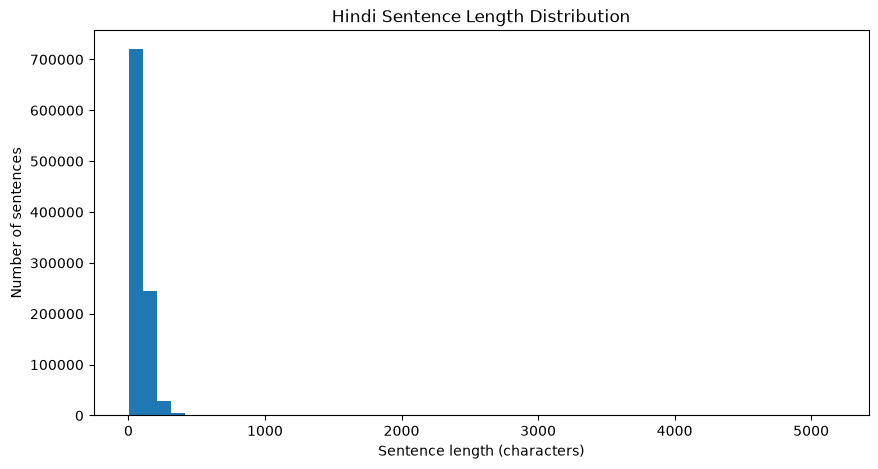

In [112]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["length_chars"],
    bins=50
)

plt.xlabel("Sentence length (characters)")
plt.ylabel("Number of sentences")
plt.title("Hindi Sentence Length Distribution")

plt.show()

### Bucket sentence lengths
This block groups sentences into quantile bins so the train, development, and test sets stay balanced.

In [ ]:
df["length_bin"] = pd.qcut(
    df["length_chars"],
    q=20,
    labels=False,
    duplicates="drop"
)

print(
    df["length_bin"].value_counts().sort_index()
)

TRAIN
count    1.000002e+06
mean     8.924105e+01
std      6.573614e+01
min      3.000000e+00
25%      5.100000e+01
50%      7.700000e+01
75%      1.120000e+02
max      5.163000e+03
Name: length_chars, dtype: float64

DEVELOPMENT
count    1000.000000
mean       88.395000
std        55.825079
min         3.000000
25%        51.000000
50%        77.000000
75%       112.000000
max       487.000000
Name: length_chars, dtype: float64

TEST
count    1000.000000
mean       88.303000
std        57.180056
min         3.000000
25%        51.000000
50%        77.000000
75%       112.000000
max       692.000000
Name: length_chars, dtype: float64


### Bucket sentence lengths
This block groups sentences into quantile bins so the train, development, and test sets stay balanced.

In [46]:
SEED = 42

dev_df = (
    df.groupby("length_bin", group_keys=False)
      .apply(
          lambda x: x.sample(
              n=max(
                  1,
                  round(len(x) / len(df) * 1000)
              ),
              random_state=SEED
          )
      )
)

### Run the next analysis step
This cell performs the next stage of the tokenizer experiment and helps interpret the model behavior.

In [47]:
dev_df = dev_df.sample(
    n=1000,
    random_state=SEED
).reset_index(drop=True)

print("Development sentences:", len(dev_df))

Development sentences: 1000


### Create validation and test sets
This cell splits the data while preserving the sentence-length distribution across subsets.

In [48]:
remaining_df = df.drop(
    dev_df.index,
    errors="ignore"
)

### Bucket sentence lengths
This block groups sentences into quantile bins so the train, development, and test sets stay balanced.

In [49]:
dev_sample = df.groupby(
    "length_bin",
    group_keys=False
).apply(
    lambda x: x.sample(
        frac=1000 / len(df),
        random_state=SEED
    )
)

dev_sample = dev_sample.sample(
    n=1000,
    random_state=SEED
)

dev_df = dev_sample.reset_index(drop=True)

remaining_df = df.drop(
    dev_sample.index
)

print("Development:", len(dev_df))
print("Remaining:", len(remaining_df))

Development: 1000
Remaining: 1001002


### Bucket sentence lengths
This block groups sentences into quantile bins so the train, development, and test sets stay balanced.

In [50]:
test_sample = remaining_df.groupby(
    "length_bin",
    group_keys=False
).apply(
    lambda x: x.sample(
        frac=1000 / len(remaining_df),
        random_state=SEED + 1
    )
)

test_sample = test_sample.sample(
    n=1000,
    random_state=SEED + 1
)

test_df = test_sample.reset_index(drop=True)

remaining_df = remaining_df.drop(
    test_sample.index
)

print("Test:", len(test_df))
print("Remaining:", len(remaining_df))

Test: 1000
Remaining: 1000002


### Create validation and test sets
This cell splits the data while preserving the sentence-length distribution across subsets.

In [51]:
train_df = remaining_df.reset_index(drop=True)

print("Training:", len(train_df))
print("Development:", len(dev_df))
print("Test:", len(test_df))

Training: 1000002
Development: 1000
Test: 1000


### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

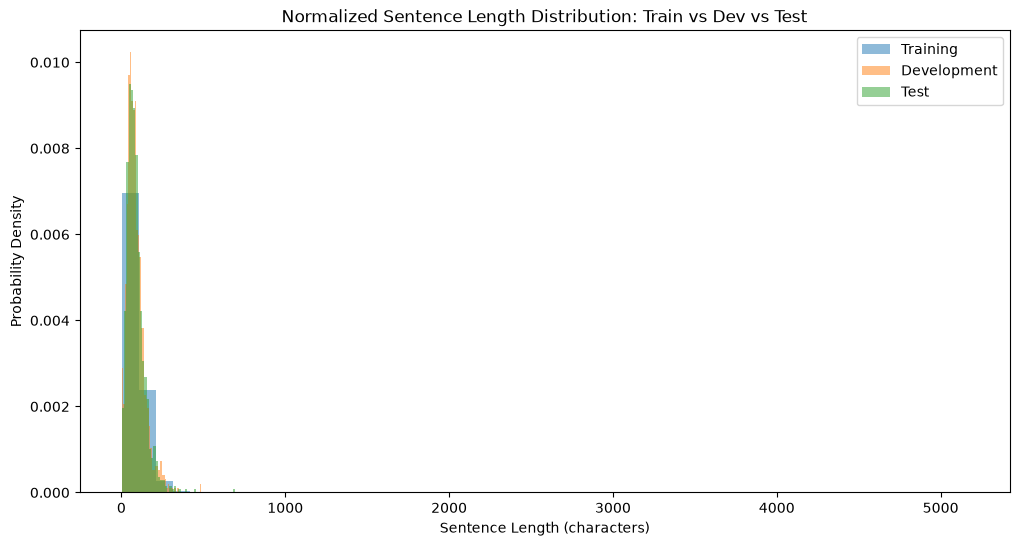

In [59]:
plt.figure(figsize=(12, 6))

plt.hist(
    train_df["length_chars"],
    bins=50,
    density=True,
    alpha=0.5,
    label="Training"
)

plt.hist(
    dev_df["length_chars"],
    bins=50,
    density=True,
    alpha=0.5,
    label="Development"
)

plt.hist(
    test_df["length_chars"],
    bins=50,
    density=True,
    alpha=0.5,
    label="Test"
)

plt.xlabel("Sentence Length (characters)")
plt.ylabel("Probability Density")

plt.title(
    "Normalized Sentence Length Distribution: Train vs Dev vs Test"
)

plt.legend()

plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

99th percentile: 291.0


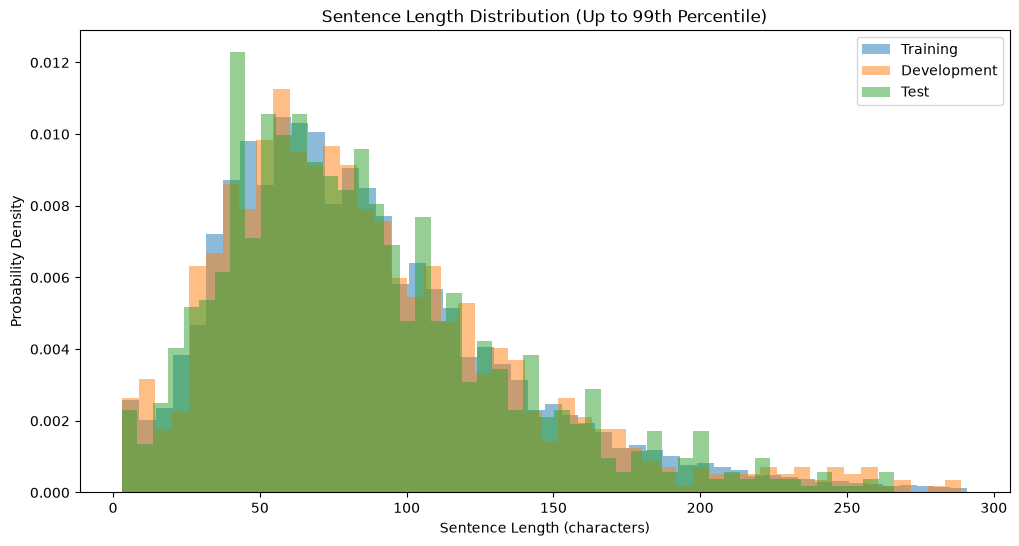

In [61]:
upper_limit = train_df["length_chars"].quantile(0.99)

print("99th percentile:", upper_limit)

plt.figure(figsize=(12, 6))

plt.hist(
    train_df[
        train_df["length_chars"] <= upper_limit
    ]["length_chars"],
    bins=50,
    density=True,
    alpha=0.5,
    label="Training"
)

plt.hist(
    dev_df[
        dev_df["length_chars"] <= upper_limit
    ]["length_chars"],
    bins=50,
    density=True,
    alpha=0.5,
    label="Development"
)

plt.hist(
    test_df[
        test_df["length_chars"] <= upper_limit
    ]["length_chars"],
    bins=50,
    density=True,
    alpha=0.5,
    label="Test"
)

plt.xlabel("Sentence Length (characters)")
plt.ylabel("Probability Density")

plt.title(
    "Sentence Length Distribution "
    "(Up to 99th Percentile)"
)

plt.legend()

plt.show()

### Prepare the training split
This block sets aside the remaining sentences for training and prints the final dataset sizes.

In [53]:
print("TRAIN")
print(train_df.head())
print(train_df.columns)
print()

print("DEV")
print(dev_df.head())
print(dev_df.columns)
print()

print("TEST")
print(test_df.head())
print(test_df.columns)

TRAIN
                                            sentence  length_chars  \
0      लोगों को बिलों संबंधी सुविधा देना ही उनका काम            45   
1  इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...           155   
2  हालांकि तब पार्टी पर देवीलाल की मजबूत पकड़ के ...            76   
3  1989 में देवीलाल केन्द्र की राजनीति में सक्रिय...           243   
4  उन परिस्थितियों में देवीलाल ने कड़ा निर्णय लेत...           178   

   length_words  length_bin  
0             9           3  
1            27          17  
2            16           9  
3            46          19  
4            35          18  
Index(['sentence', 'length_chars', 'length_words', 'length_bin'], dtype='str')

DEV
                                            sentence  length_chars  \
0  केंद्रीय मंत्री मुख्तार अब्बास नकवी ने ट्वीट क...            80   
1  ऐसे में धनछो से लेकर मणिमहेश डल तक शौचालय की उ...           172   
2  इसमें पहला कैमरा f/2.2 अपर्चर के साथ 13 मेगापि...           105   
3  हमास ने कहा कि जिस तरह फ़ि

### Summarize sentence length
This cell reports descriptive statistics for sentence lengths and gives a quick sense of the distribution.

In [54]:
print("Training length:")
print(train_df["length_chars"].describe())

print("\nDevelopment length:")
print(dev_df["length_chars"].describe())

print("\nTest length:")
print(test_df["length_chars"].describe())

Training length:
count    1.000002e+06
mean     8.924105e+01
std      6.573614e+01
min      3.000000e+00
25%      5.100000e+01
50%      7.700000e+01
75%      1.120000e+02
max      5.163000e+03
Name: length_chars, dtype: float64

Development length:
count    1000.000000
mean       88.395000
std        55.825079
min         3.000000
25%        51.000000
50%        77.000000
75%       112.000000
max       487.000000
Name: length_chars, dtype: float64

Test length:
count    1000.000000
mean       88.303000
std        57.180056
min         3.000000
25%        51.000000
50%        77.000000
75%       112.000000
max       692.000000
Name: length_chars, dtype: float64


### Summarize sentence length
This cell reports descriptive statistics for sentence lengths and gives a quick sense of the distribution.

In [57]:
print("TRAIN")
print(train_df["length_chars"].describe())

print("\nDEVELOPMENT")
print(dev_df["length_chars"].describe())

print("\nTEST")
print(test_df["length_chars"].describe())

TRAIN
count    1.000002e+06
mean     8.924105e+01
std      6.573614e+01
min      3.000000e+00
25%      5.100000e+01
50%      7.700000e+01
75%      1.120000e+02
max      5.163000e+03
Name: length_chars, dtype: float64

DEVELOPMENT
count    1000.000000
mean       88.395000
std        55.825079
min         3.000000
25%        51.000000
50%        77.000000
75%       112.000000
max       487.000000
Name: length_chars, dtype: float64

TEST
count    1000.000000
mean       88.303000
std        57.180056
min         3.000000
25%        51.000000
50%        77.000000
75%       112.000000
max       692.000000
Name: length_chars, dtype: float64


### Prepare the training split
This block sets aside the remaining sentences for training and prints the final dataset sizes.

In [58]:
print("Top 20 longest training sentences:")
print(
    train_df.nlargest(20, "length_chars")[
        ["sentence", "length_chars"]
    ]
)

Top 20 longest training sentences:
                                                 sentence  length_chars
101779  : Dhoop Mei Kapde Sukhane Ke Kya Fayde Hai | D...          5163
934617  आर डी शुक्ला द्वारा अगस्त 2019 का महीना भारत क...          4654
873728  इसे भी पढ़ें :उज्ज्वला योजना: 14 लाख गरीबों को...          4466
62115   अच्छी सेहत बनाये रखने के लिए स्वस्थ भोजन करना ...          4394
114990  जिस तरह से हम अपने शरीर को मजबूत करते हैं जिसस...          4144
729832  चुनार में चुनार का किला बहुत ही प्रसिद्ध है तथ...          4116
939894  हम सब बच्चे पैदा करने से डरते हैं क्यूंकि हम ज...          3969
434641  उत्तराखंड सामान्य ज्ञान की इस पोस्ट में माँ पू...          3928
876864  किसी नदी के बैंकों से पैसे लेकर डॉक्यूमेंट वेर...          3882
608680  विवेक राजपूत झाँसी/ झांसी जिले की आबकारी विभाग...          3720
331287  अगर आपका वजन बहुत ज्यादा है तो आपको घबराने की ...          3533
668925  न सिर्फ लोगों कि बनाएँ बांग्लादेश और वेस्टइंडी...          3509
16198   सुल्तानपुर उत्तर प्रद

### Prepare the training split
This block sets aside the remaining sentences for training and prints the final dataset sizes.

In [62]:
print("Training:", len(train_df))
print("Development:", len(dev_df))
print("Test:", len(test_df))

print("\nExample training sentence:")
print(train_df.iloc[0]["sentence"])

print("\nExample development sentence:")
print(dev_df.iloc[0]["sentence"])

print("\nExample test sentence:")
print(test_df.iloc[0]["sentence"])

Training: 1000002
Development: 1000
Test: 1000

Example training sentence:
लोगों को बिलों संबंधी सुविधा देना ही उनका काम

Example development sentence:
केंद्रीय मंत्री मुख्तार अब्बास नकवी ने ट्वीट किया, 'शशि थरूर भाई तो लव गुरू हैं.

Example test sentence:
चैपल ने कहा कि बर्न्स भी सिब्ली की तरह ही है और अगर ये दोनों नाकाम रहते हैं और जो रूट वर्तमान फॉर्म बरकरार नहीं रख पाते हैं तो इंग्लैंड मुश्किल में पड़ जाएगा।


### Define the experiment grid
This block sets the training sizes and vocabulary sizes to compare tokenizer behavior across multiple conditions.

In [63]:
TRAINING_SIZES = [
    100_000,
    300_000,
    500_000,
    1_000_000
]

VOCAB_SIZES = [
    20_000,
    30_000,
    50_000
]

print("Training sizes:", TRAINING_SIZES)
print("Vocabulary sizes:", VOCAB_SIZES)

Training sizes: [100000, 300000, 500000, 1000000]
Vocabulary sizes: [20000, 30000, 50000]


### Prepare tokenizer storage
This cell creates the folder where trained tokenizer files will be saved.

In [66]:
TOKENIZER_DIR = "trained_tokenizers"

os.makedirs(
    TOKENIZER_DIR,
    exist_ok=True
)

print("Tokenizer directory ready.")

Tokenizer directory ready.


### Prepare tokenizer storage
This cell creates the folder where trained tokenizer files will be saved.

In [67]:
def train_bpe(
    training_sentences,
    training_size,
    vocab_size
):
    
    filename = (
        f"{TOKENIZER_DIR}/"
        f"bpe_{training_size}_{vocab_size}.json"
    )
    
    # If already trained, load it
    if os.path.exists(filename):
        print(f"Loading existing tokenizer: {filename}")
        
        return Tokenizer.from_file(filename)
    
    print(
        f"\nTraining BPE | "
        f"Data={training_size:,} | "
        f"Vocab={vocab_size:,}"
    )
    
    tokenizer = Tokenizer(
        BPE(
            unk_token="[UNK]"
        )
    )
    
    # Normalize Unicode text
    tokenizer.normalizer = NFKC()
    
    # Split into words before BPE learns subword merges
    tokenizer.pre_tokenizer = Whitespace()
    
    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=[
            "[PAD]",
            "[UNK]",
            "[CLS]",
            "[SEP]",
            "[MASK]"
        ],
        show_progress=True
    )
    
    tokenizer.train_from_iterator(
        training_sentences,
        trainer=trainer,
        length=training_size
    )
    
    tokenizer.save(filename)
    
    print("Saved:", filename)
    
    return tokenizer

### Prepare the training split
This block sets aside the remaining sentences for training and prints the final dataset sizes.

In [68]:
bpe_test = train_bpe(
    train_df["sentence"].iloc[:100_000],
    100_000,
    20_000
)


Training BPE | Data=100,000 | Vocab=20,000



Saved: trained_tokenizers/bpe_100000_20000.json


### Check tokenizer vocabulary
This block verifies that the tokenizer learned the expected number of entries.

In [69]:
print(
    "Vocabulary size:",
    bpe_test.get_vocab_size()
)

Vocabulary size: 20000


### Inspect BPE output
This cell tokenizes a sample sentence and shows the resulting BPE subword pieces.

In [70]:
sample_sentence = dev_df.iloc[0]["sentence"]

print("Original:")
print(sample_sentence)

encoding = bpe_test.encode(sample_sentence)

print("\nBPE tokens:")
print(encoding.tokens)

print("\nNumber of tokens:")
print(len(encoding.tokens))

Original:
केंद्रीय मंत्री मुख्तार अब्बास नकवी ने ट्वीट किया, 'शशि थरूर भाई तो लव गुरू हैं.

BPE tokens:
['केंद्रीय', 'मंत्री', 'मुख्तार', 'अब्बास', 'नकवी', 'ने', 'ट्वीट', 'किया', ',', "'", 'शशि', 'थरूर', 'भाई', 'तो', 'लव', 'गुरू', 'हैं', '.']

Number of tokens:
18


### Prepare tokenizer storage
This cell creates the folder where trained tokenizer files will be saved.

In [71]:
def train_wordpiece(
    training_sentences,
    training_size,
    vocab_size
):
    
    filename = (
        f"{TOKENIZER_DIR}/"
        f"wordpiece_{training_size}_{vocab_size}.json"
    )
    
    # Load existing tokenizer if available
    if os.path.exists(filename):
        print(f"Loading existing tokenizer: {filename}")
        
        return Tokenizer.from_file(filename)
    
    print(
        f"\nTraining WordPiece | "
        f"Data={training_size:,} | "
        f"Vocab={vocab_size:,}"
    )
    
    tokenizer = Tokenizer(
        WordPiece(
            unk_token="[UNK]"
        )
    )
    
    tokenizer.normalizer = NFKC()
    
    tokenizer.pre_tokenizer = Whitespace()
    
    trainer = WordPieceTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=[
            "[PAD]",
            "[UNK]",
            "[CLS]",
            "[SEP]",
            "[MASK]"
        ],
        show_progress=True
    )
    
    tokenizer.train_from_iterator(
        training_sentences,
        trainer=trainer,
        length=training_size
    )
    
    tokenizer.save(filename)
    
    print("Saved:", filename)
    
    return tokenizer

### Prepare the training split
This block sets aside the remaining sentences for training and prints the final dataset sizes.

In [72]:
wordpiece_test = train_wordpiece(
    train_df["sentence"].iloc[:100_000],
    100_000,
    20_000
)


Training WordPiece | Data=100,000 | Vocab=20,000



Saved: trained_tokenizers/wordpiece_100000_20000.json


### Check tokenizer vocabulary
This block verifies that the tokenizer learned the expected number of entries.

In [73]:
print(
    "Vocabulary size:",
    wordpiece_test.get_vocab_size()
)

Vocabulary size: 20000


### Inspect WordPiece output
This block tokenizes the same sample sentence and displays the WordPiece fragments.

In [74]:
encoding = wordpiece_test.encode(
    dev_df.iloc[0]["sentence"]
)

print("Original:")
print(dev_df.iloc[0]["sentence"])

print("\nWordPiece:")
print(encoding.tokens)

print("\nNumber of tokens:")
print(len(encoding.tokens))

Original:
केंद्रीय मंत्री मुख्तार अब्बास नकवी ने ट्वीट किया, 'शशि थरूर भाई तो लव गुरू हैं.

WordPiece:
['केंद्रीय', 'मंत्री', 'मुख्तार', 'अब्बास', 'नक', '##वी', 'ने', 'ट्वीट', 'किया', ',', "'", 'शशि', 'थरूर', 'भाई', 'तो', 'लव', 'गुरू', 'हैं', '.']

Number of tokens:
19


### Compare tokenization styles
This cell compares BPE and WordPiece segmentation on the same sentence.

In [75]:
sentence = dev_df.iloc[0]["sentence"]

bpe_tokens = bpe_test.encode(sentence).tokens
wp_tokens = wordpiece_test.encode(sentence).tokens

print("ORIGINAL SENTENCE")
print(sentence)

print("\n" + "=" * 70)

print("BPE")
print(bpe_tokens)

print("Number of BPE tokens:", len(bpe_tokens))

print("\n" + "=" * 70)

print("WORDPIECE")
print(wp_tokens)

print("Number of WordPiece tokens:", len(wp_tokens))

ORIGINAL SENTENCE
केंद्रीय मंत्री मुख्तार अब्बास नकवी ने ट्वीट किया, 'शशि थरूर भाई तो लव गुरू हैं.

BPE
['केंद्रीय', 'मंत्री', 'मुख्तार', 'अब्बास', 'नकवी', 'ने', 'ट्वीट', 'किया', ',', "'", 'शशि', 'थरूर', 'भाई', 'तो', 'लव', 'गुरू', 'हैं', '.']
Number of BPE tokens: 18

WORDPIECE
['केंद्रीय', 'मंत्री', 'मुख्तार', 'अब्बास', 'नक', '##वी', 'ने', 'ट्वीट', 'किया', ',', "'", 'शशि', 'थरूर', 'भाई', 'तो', 'लव', 'गुरू', 'हैं', '.']
Number of WordPiece tokens: 19


### Define evaluation metrics
This function measures token count, unknown-token count, and average characters per token for each tokenizer.

In [76]:
def evaluate_tokenizer(
    tokenizer,
    sentences,
    dataset_name
):
    
    total_tokens = 0
    total_characters = 0
    total_unknown = 0
    
    token_counts = []
    
    for sentence in sentences:
        
        encoding = tokenizer.encode(sentence)
        
        tokens = encoding.tokens
        
        token_count = len(tokens)
        
        total_tokens += token_count
        total_characters += len(sentence)
        
        total_unknown += tokens.count("[UNK]")
        
        token_counts.append(token_count)
    
    return {
        "Dataset": dataset_name,
        "Sentences": len(sentences),
        "Total Tokens": total_tokens,
        "Average Tokens/Sentence": np.mean(token_counts),
        "Average Characters/Token": (
            total_characters / total_tokens
            if total_tokens > 0
            else 0
        ),
        "UNK Tokens": total_unknown
    }

### Evaluate BPE on evaluation sets
This cell measures how effectively the BPE tokenizer compresses text across the development and test splits.

In [77]:
bpe_dev_result = evaluate_tokenizer(
    bpe_test,
    dev_df["sentence"],
    "Development"
)

bpe_test_result = evaluate_tokenizer(
    bpe_test,
    test_df["sentence"],
    "Test"
)

pd.DataFrame([
    bpe_dev_result,
    bpe_test_result
])

,Dataset,Sentences,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens
0,Development,1000,20959,20.959,4.217520,1
1,Test,1000,21092,21.092,4.186564,0


### Evaluate WordPiece on evaluation sets
This cell measures how effectively the WordPiece tokenizer compresses text across the development and test splits.

In [79]:
wp_dev_result = evaluate_tokenizer(
    wordpiece_test,
    dev_df["sentence"],
    "Development"
)

wp_test_result = evaluate_tokenizer(
    wordpiece_test,
    test_df["sentence"],
    "Test"
)

pd.DataFrame([
    wp_dev_result,
    wp_test_result
])

,Dataset,Sentences,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens
0,Development,1000,21242,21.242,4.161331,1
1,Test,1000,21371,21.371,4.131908,0


### Prepare the training split
This block sets aside the remaining sentences for training and prints the final dataset sizes.

In [80]:
bpe_results = []

for training_size in TRAINING_SIZES:
    
    for vocab_size in VOCAB_SIZES:
        
        print("\n" + "=" * 80)
        print(
            f"BPE experiment: "
            f"{training_size:,} sentences | "
            f"{vocab_size:,} vocabulary"
        )
        print("=" * 80)
        
        tokenizer = train_bpe(
            train_df["sentence"].iloc[:training_size],
            training_size,
            vocab_size
        )
        
        dev_result = evaluate_tokenizer(
            tokenizer,
            dev_df["sentence"],
            "Development"
        )
        
        test_result = evaluate_tokenizer(
            tokenizer,
            test_df["sentence"],
            "Test"
        )
        
        for result in [dev_result, test_result]:
            
            result["Algorithm"] = "BPE"
            result["Training Size"] = training_size
            result["Vocabulary Size"] = vocab_size
            
            bpe_results.append(result)


BPE experiment: 100,000 sentences | 20,000 vocabulary
Loading existing tokenizer: trained_tokenizers/bpe_100000_20000.json

BPE experiment: 100,000 sentences | 30,000 vocabulary

Training BPE | Data=100,000 | Vocab=30,000



Saved: trained_tokenizers/bpe_100000_30000.json

BPE experiment: 100,000 sentences | 50,000 vocabulary

Training BPE | Data=100,000 | Vocab=50,000



Saved: trained_tokenizers/bpe_100000_50000.json

BPE experiment: 300,000 sentences | 20,000 vocabulary

Training BPE | Data=300,000 | Vocab=20,000



Saved: trained_tokenizers/bpe_300000_20000.json

BPE experiment: 300,000 sentences | 30,000 vocabulary

Training BPE | Data=300,000 | Vocab=30,000



Saved: trained_tokenizers/bpe_300000_30000.json

BPE experiment: 300,000 sentences | 50,000 vocabulary

Training BPE | Data=300,000 | Vocab=50,000



Saved: trained_tokenizers/bpe_300000_50000.json

BPE experiment: 500,000 sentences | 20,000 vocabulary

Training BPE | Data=500,000 | Vocab=20,000



Saved: trained_tokenizer

### Create the analysis table
This block builds a dataframe of sentences and adds character and word-length features for analysis.

In [81]:
bpe_results_df = pd.DataFrame(
    bpe_results
)

bpe_results_df

,Dataset,Sentences,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens,Algorithm,Training Size,Vocabulary Size
0,Development,1000,20959,20.959,4.217520,1,BPE,100000,20000
1,Test,1000,21092,21.092,4.186564,0,BPE,100000,20000
2,Development,1000,20458,20.458,4.320804,1,BPE,100000,30000
3,Test,1000,20620,20.620,4.282396,0,BPE,100000,30000
4,Development,1000,20073,20.073,4.403677,1,BPE,100000,50000
5,Test,1000,20262,20.262,4.358059,0,BPE,100000,50000
6,Development,1000,20914,20.914,4.226595,0,BPE,300000,20000
7,Test,1000,21067,21.067,4.191532,0,BPE,300000,20000
8,Development,1000,20381,20.381,4.337128,0,BPE,300000,30000
9,Test,1000,20547,20.547,4.297610,0,BPE,300000,30000


### Inspect BPE results
This block converts the BPE experiment records into a dataframe for comparison.

In [82]:
bpe_results_df.to_csv(
    "BPE_results.csv",
    index=False
)

### Prepare the training split
This block sets aside the remaining sentences for training and prints the final dataset sizes.

In [83]:
wordpiece_results = []

for training_size in TRAINING_SIZES:
    
    for vocab_size in VOCAB_SIZES:
        
        print("\n" + "=" * 80)
        print(
            f"WordPiece experiment: "
            f"{training_size:,} sentences | "
            f"{vocab_size:,} vocabulary"
        )
        print("=" * 80)
        
        tokenizer = train_wordpiece(
            train_df["sentence"].iloc[:training_size],
            training_size,
            vocab_size
        )
        
        dev_result = evaluate_tokenizer(
            tokenizer,
            dev_df["sentence"],
            "Development"
        )
        
        test_result = evaluate_tokenizer(
            tokenizer,
            test_df["sentence"],
            "Test"
        )
        
        for result in [dev_result, test_result]:
            
            result["Algorithm"] = "WordPiece"
            result["Training Size"] = training_size
            result["Vocabulary Size"] = vocab_size
            
            wordpiece_results.append(result)


WordPiece experiment: 100,000 sentences | 20,000 vocabulary
Loading existing tokenizer: trained_tokenizers/wordpiece_100000_20000.json

WordPiece experiment: 100,000 sentences | 30,000 vocabulary

Training WordPiece | Data=100,000 | Vocab=30,000



Saved: trained_tokenizers/wordpiece_100000_30000.json

WordPiece experiment: 100,000 sentences | 50,000 vocabulary

Training WordPiece | Data=100,000 | Vocab=50,000



Saved: trained_tokenizers/wordpiece_100000_50000.json

WordPiece experiment: 300,000 sentences | 20,000 vocabulary

Training WordPiece | Data=300,000 | Vocab=20,000



Saved: trained_tokenizers/wordpiece_300000_20000.json

WordPiece experiment: 300,000 sentences | 30,000 vocabulary

Training WordPiece | Data=300,000 | Vocab=30,000



Saved: trained_tokenizers/wordpiece_300000_30000.json

WordPiece experiment: 300,000 sentences | 50,000 vocabulary

Training WordPiece | Data=300,000 | Vocab=50,000



Saved: trained_tokenizers/wordpiece_300000_50000.json

WordPiece experiment: 5

### Create the analysis table
This block builds a dataframe of sentences and adds character and word-length features for analysis.

In [84]:
wordpiece_results_df = pd.DataFrame(
    wordpiece_results
)

wordpiece_results_df

,Dataset,Sentences,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens,Algorithm,Training Size,Vocabulary Size
0,Development,1000,21242,21.242,4.161331,1,WordPiece,100000,20000
1,Test,1000,21371,21.371,4.131908,0,WordPiece,100000,20000
2,Development,1000,20628,20.628,4.285195,1,WordPiece,100000,30000
3,Test,1000,20817,20.817,4.241870,0,WordPiece,100000,30000
4,Development,1000,20166,20.166,4.383368,1,WordPiece,100000,50000
5,Test,1000,20385,20.385,4.331764,0,WordPiece,100000,50000
6,Development,1000,21203,21.203,4.168986,0,WordPiece,300000,20000
7,Test,1000,21343,21.343,4.137328,0,WordPiece,300000,20000
8,Development,1000,20573,20.573,4.296651,0,WordPiece,300000,30000
9,Test,1000,20749,20.749,4.255771,0,WordPiece,300000,30000


### Inspect WordPiece results
This block converts the WordPiece experiment records into a dataframe for analysis.

In [85]:
wordpiece_results_df.to_csv(
    "WordPiece_results.csv",
    index=False
)

### Inspect BPE results
This block converts the BPE experiment records into a dataframe for comparison.

In [86]:
all_results = pd.concat(
    [
        bpe_results_df,
        wordpiece_results_df
    ],
    ignore_index=True
)

all_results.head()

,Dataset,Sentences,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens,Algorithm,Training Size,Vocabulary Size
0,Development,1000,20959,20.959,4.217520,1,BPE,100000,20000
1,Test,1000,21092,21.092,4.186564,0,BPE,100000,20000
2,Development,1000,20458,20.458,4.320804,1,BPE,100000,30000
3,Test,1000,20620,20.620,4.282396,0,BPE,100000,30000
4,Development,1000,20073,20.073,4.403677,1,BPE,100000,50000


### Save the combined results
This block exports the consolidated tokenizer evaluation table.

In [87]:
all_results.to_csv(
    "final_tokenization_results.csv",
    index=False
)

### Filter development results
This cell keeps only the development-set metrics to compare model behavior under the same validation conditions.

In [88]:
dev_results = all_results[
    all_results["Dataset"] == "Development"
]

dev_results

,Dataset,Sentences,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens,Algorithm,Training Size,Vocabulary Size
0,Development,1000,20959,20.959,4.217520,1,BPE,100000,20000
2,Development,1000,20458,20.458,4.320804,1,BPE,100000,30000
4,Development,1000,20073,20.073,4.403677,1,BPE,100000,50000
6,Development,1000,20914,20.914,4.226595,0,BPE,300000,20000
8,Development,1000,20381,20.381,4.337128,0,BPE,300000,30000
10,Development,1000,19982,19.982,4.423731,0,BPE,300000,50000
12,Development,1000,20919,20.919,4.225584,0,BPE,500000,20000
14,Development,1000,20374,20.374,4.338618,0,BPE,500000,30000
16,Development,1000,19940,19.940,4.433049,0,BPE,500000,50000
18,Development,1000,20916,20.916,4.226190,0,BPE,1000000,20000


### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

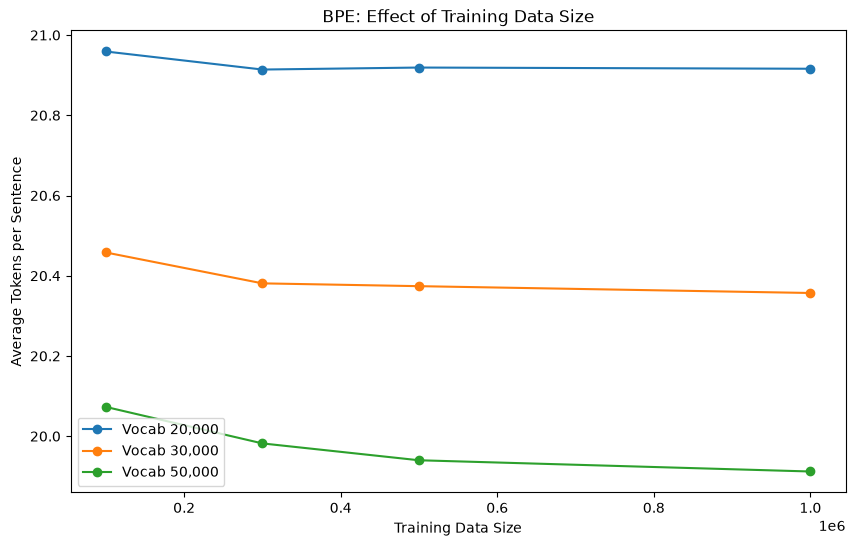

In [89]:
import matplotlib.pyplot as plt

bpe_dev = dev_results[
    dev_results["Algorithm"] == "BPE"
]

plt.figure(figsize=(10, 6))

for vocab_size in VOCAB_SIZES:
    
    subset = bpe_dev[
        bpe_dev["Vocabulary Size"] == vocab_size
    ]
    
    plt.plot(
        subset["Training Size"],
        subset["Average Tokens/Sentence"],
        marker="o",
        label=f"Vocab {vocab_size:,}"
    )

plt.xlabel("Training Data Size")
plt.ylabel("Average Tokens per Sentence")

plt.title(
    "BPE: Effect of Training Data Size"
)

plt.legend()

plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

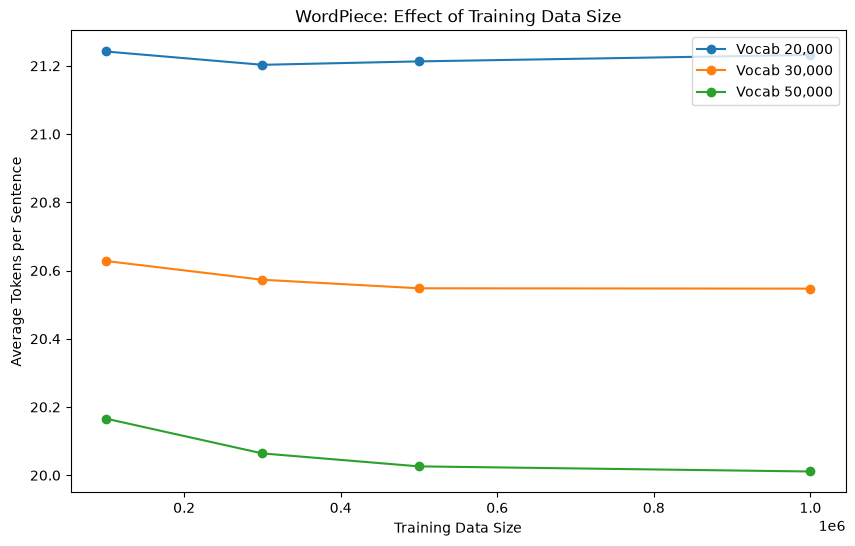

In [90]:
wp_dev = dev_results[
    dev_results["Algorithm"] == "WordPiece"
]

plt.figure(figsize=(10, 6))

for vocab_size in VOCAB_SIZES:
    
    subset = wp_dev[
        wp_dev["Vocabulary Size"] == vocab_size
    ]
    
    plt.plot(
        subset["Training Size"],
        subset["Average Tokens/Sentence"],
        marker="o",
        label=f"Vocab {vocab_size:,}"
    )

plt.xlabel("Training Data Size")
plt.ylabel("Average Tokens per Sentence")

plt.title(
    "WordPiece: Effect of Training Data Size"
)

plt.legend()

plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

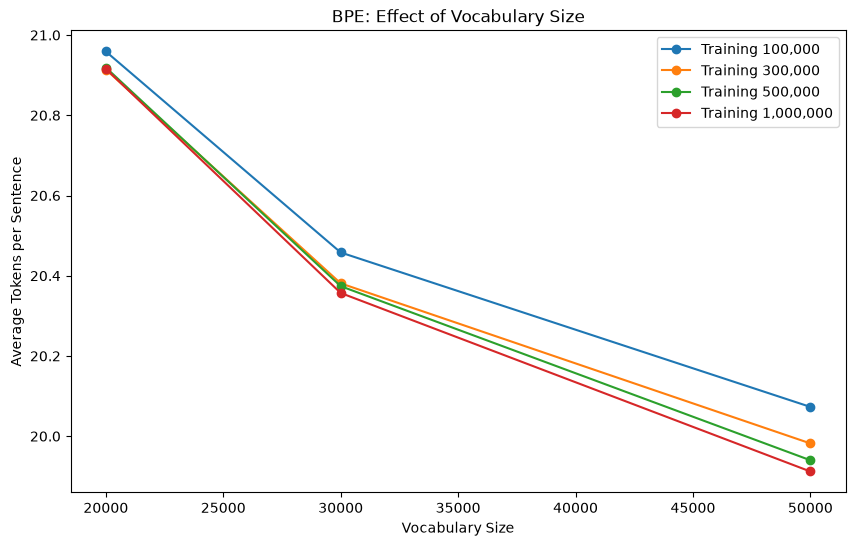

In [91]:
plt.figure(figsize=(10, 6))

for training_size in TRAINING_SIZES:
    
    subset = bpe_dev[
        bpe_dev["Training Size"] == training_size
    ]
    
    plt.plot(
        subset["Vocabulary Size"],
        subset["Average Tokens/Sentence"],
        marker="o",
        label=f"Training {training_size:,}"
    )

plt.xlabel("Vocabulary Size")
plt.ylabel("Average Tokens per Sentence")

plt.title(
    "BPE: Effect of Vocabulary Size"
)

plt.legend()

plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

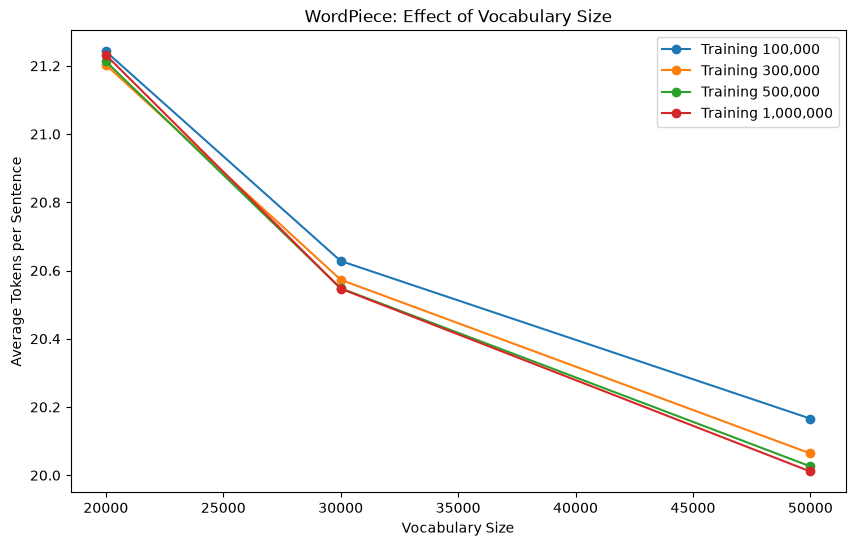

In [92]:
plt.figure(figsize=(10, 6))

for training_size in TRAINING_SIZES:
    
    subset = wp_dev[
        wp_dev["Training Size"] == training_size
    ]
    
    plt.plot(
        subset["Vocabulary Size"],
        subset["Average Tokens/Sentence"],
        marker="o",
        label=f"Training {training_size:,}"
    )

plt.xlabel("Vocabulary Size")
plt.ylabel("Average Tokens per Sentence")

plt.title(
    "WordPiece: Effect of Vocabulary Size"
)

plt.legend()

plt.show()

### Compare the 1M-token setting
This cell summarizes the strongest configurations at the largest training size.

In [93]:
comparison_1m = dev_results[
    dev_results["Training Size"] == 1_000_000
]

comparison_1m[
    [
        "Algorithm",
        "Vocabulary Size",
        "Average Tokens/Sentence",
        "Average Characters/Token",
        "UNK Tokens"
    ]
].sort_values(
    ["Vocabulary Size", "Algorithm"]
)

,Algorithm,Vocabulary Size,Average Tokens/Sentence,Average Characters/Token,UNK Tokens
18,BPE,20000,20.916,4.226190,0
42,WordPiece,20000,21.232,4.163291,0
20,BPE,30000,20.357,4.342241,0
44,WordPiece,30000,20.547,4.302088,0
22,BPE,50000,19.912,4.439283,0
46,WordPiece,50000,20.011,4.417320,0


### Preview test examples
This block prints a few test-set sentences to visually inspect the corpus.

In [94]:
sample_sentences = test_df["sentence"].iloc[:5]

for i, sentence in enumerate(sample_sentences):
    
    print("\n" + "=" * 100)
    print(f"SENTENCE {i + 1}")
    print("=" * 100)
    
    print("\nOriginal:")
    print(sentence)


SENTENCE 1

Original:
चैपल ने कहा कि बर्न्स भी सिब्ली की तरह ही है और अगर ये दोनों नाकाम रहते हैं और जो रूट वर्तमान फॉर्म बरकरार नहीं रख पाते हैं तो इंग्लैंड मुश्किल में पड़ जाएगा।

SENTENCE 2

Original:
वैसे कुछ महान लोग ऐसे भी है जो पूरी जिंदगी कमल को ये समझाने में निकाल देते है कि वो कमल है और उसे कीचढ़ में ही खिलना है ये ही उसकी किस्मत है कि वो कीचढ़ में ही रहे | और बेचारा कमल इस confusion में आजाता है कि ये मुझे convince कर रहा है या खुद को | अब जो कमल खुद को unique समझ रहा था complex हो कर depression में है | उससे भी बुरी हालत तो बेचारे कीचढ़ की है………जो इतनी बार कीचढ़ शब्द सुन कर इतना दुखी है कि वो भूल गया है कि उसमे एक बहुत खूबसूरत फूल को खिलाने की क्षमता है और वो एक ऐसा कारण है जो कमल को और फूलों से अलग करता है उसकी ख़ूबसूरती बढाता है यहाँ कुछ भी ऐसा नहीं जो बेवजह है या बेकार है , हर चीज़ की अपनी एक ख़ूबसूरती है, खासियत है।किसी के बढ़े होने का एहसास किसी के छोटे होने से ही होता है…..

SENTENCE 3

Original:
जांच के बाद मुकदमा दर्ज कर खुलासा किया जाएगा।

SENTENCE 4

Original:
जलालाबाद म

### Review the final result table
This cell shows the full evaluation table and confirms the experiment output dimensions.

In [95]:
print("Shape:", all_results.shape)

display(all_results)

Shape: (48, 9)


,Dataset,Sentences,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens,Algorithm,Training Size,Vocabulary Size
0,Development,1000,20959,20.959,4.217520,1,BPE,100000,20000
1,Test,1000,21092,21.092,4.186564,0,BPE,100000,20000
2,Development,1000,20458,20.458,4.320804,1,BPE,100000,30000
3,Test,1000,20620,20.620,4.282396,0,BPE,100000,30000
4,Development,1000,20073,20.073,4.403677,1,BPE,100000,50000
5,Test,1000,20262,20.262,4.358059,0,BPE,100000,50000
6,Development,1000,20914,20.914,4.226595,0,BPE,300000,20000
7,Test,1000,21067,21.067,4.191532,0,BPE,300000,20000
8,Development,1000,20381,20.381,4.337128,0,BPE,300000,30000
9,Test,1000,20547,20.547,4.297610,0,BPE,300000,30000


### Check result columns
This section prints the columns in the aggregated summary table.

In [96]:
print(all_results.columns.tolist())

['Dataset', 'Sentences', 'Total Tokens', 'Average Tokens/Sentence', 'Average Characters/Token', 'UNK Tokens', 'Algorithm', 'Training Size', 'Vocabulary Size']


### Save the combined results
This block exports the consolidated tokenizer evaluation table.

In [97]:
all_results.to_csv(
    "final_tokenization_results.csv",
    index=False
)

print("Saved: final_tokenization_results.csv")

Saved: final_tokenization_results.csv


### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

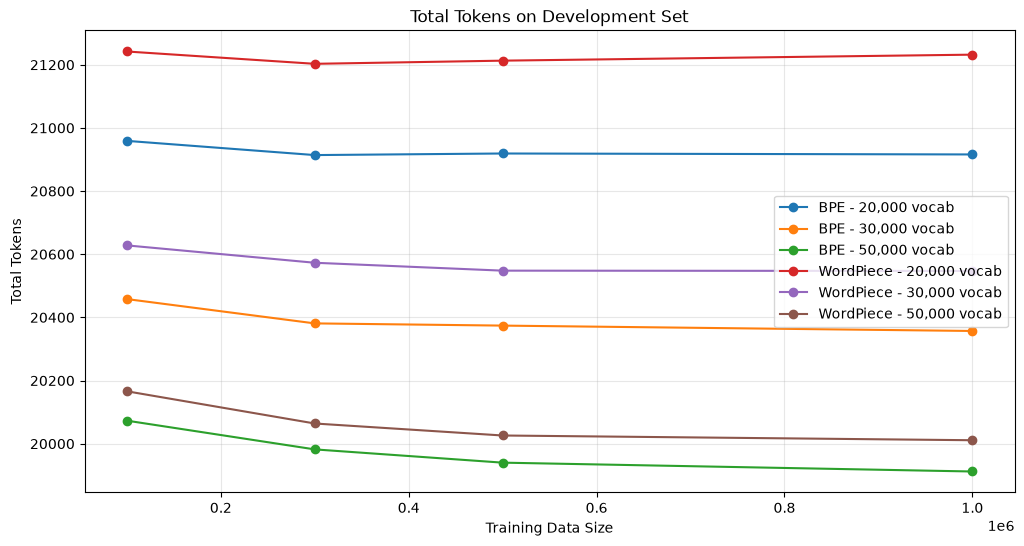

In [98]:
dev_results = all_results[
    all_results["Dataset"] == "Development"
].copy()

plt.figure(figsize=(12, 6))

for algorithm in ["BPE", "WordPiece"]:
    
    subset = dev_results[
        dev_results["Algorithm"] == algorithm
    ]
    
    for vocab_size in VOCAB_SIZES:
        
        data = subset[
            subset["Vocabulary Size"] == vocab_size
        ].sort_values("Training Size")
        
        plt.plot(
            data["Training Size"],
            data["Total Tokens"],
            marker="o",
            label=f"{algorithm} - {vocab_size:,} vocab"
        )

plt.xlabel("Training Data Size")
plt.ylabel("Total Tokens")
plt.title(
    "Total Tokens on Development Set"
)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

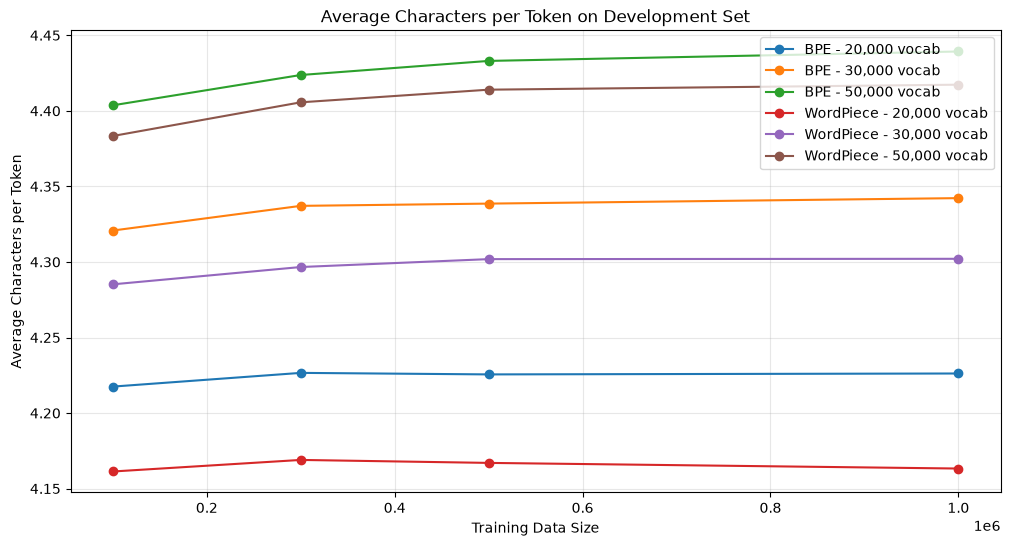

In [99]:
plt.figure(figsize=(12, 6))

for algorithm in ["BPE", "WordPiece"]:
    
    subset = dev_results[
        dev_results["Algorithm"] == algorithm
    ]
    
    for vocab_size in VOCAB_SIZES:
        
        data = subset[
            subset["Vocabulary Size"] == vocab_size
        ].sort_values("Training Size")
        
        plt.plot(
            data["Training Size"],
            data["Average Characters/Token"],
            marker="o",
            label=f"{algorithm} - {vocab_size:,} vocab"
        )

plt.xlabel("Training Data Size")
plt.ylabel("Average Characters per Token")

plt.title(
    "Average Characters per Token on Development Set"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

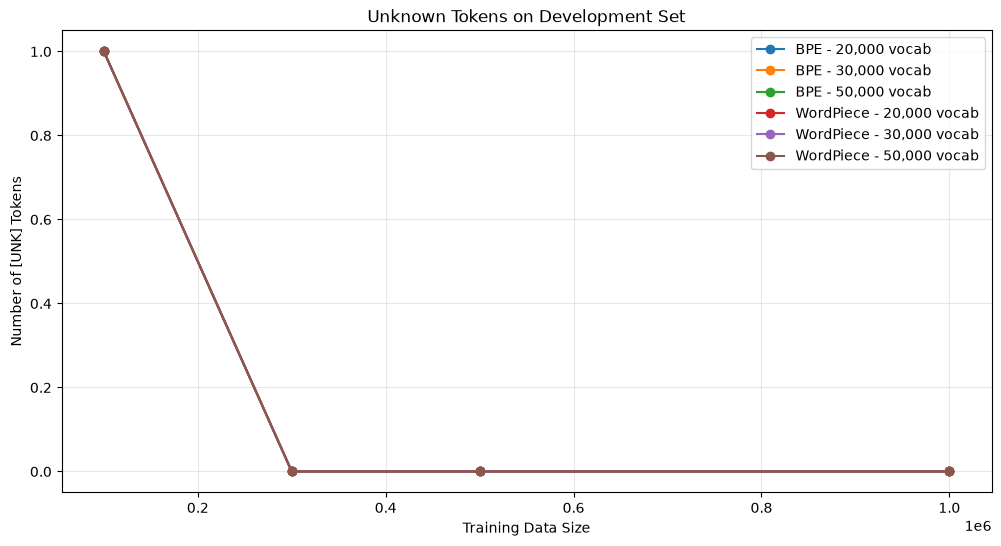

In [100]:
plt.figure(figsize=(12, 6))

for algorithm in ["BPE", "WordPiece"]:
    
    subset = dev_results[
        dev_results["Algorithm"] == algorithm
    ]
    
    for vocab_size in VOCAB_SIZES:
        
        data = subset[
            subset["Vocabulary Size"] == vocab_size
        ].sort_values("Training Size")
        
        plt.plot(
            data["Training Size"],
            data["UNK Tokens"],
            marker="o",
            label=f"{algorithm} - {vocab_size:,} vocab"
        )

plt.xlabel("Training Data Size")
plt.ylabel("Number of [UNK] Tokens")

plt.title(
    "Unknown Tokens on Development Set"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

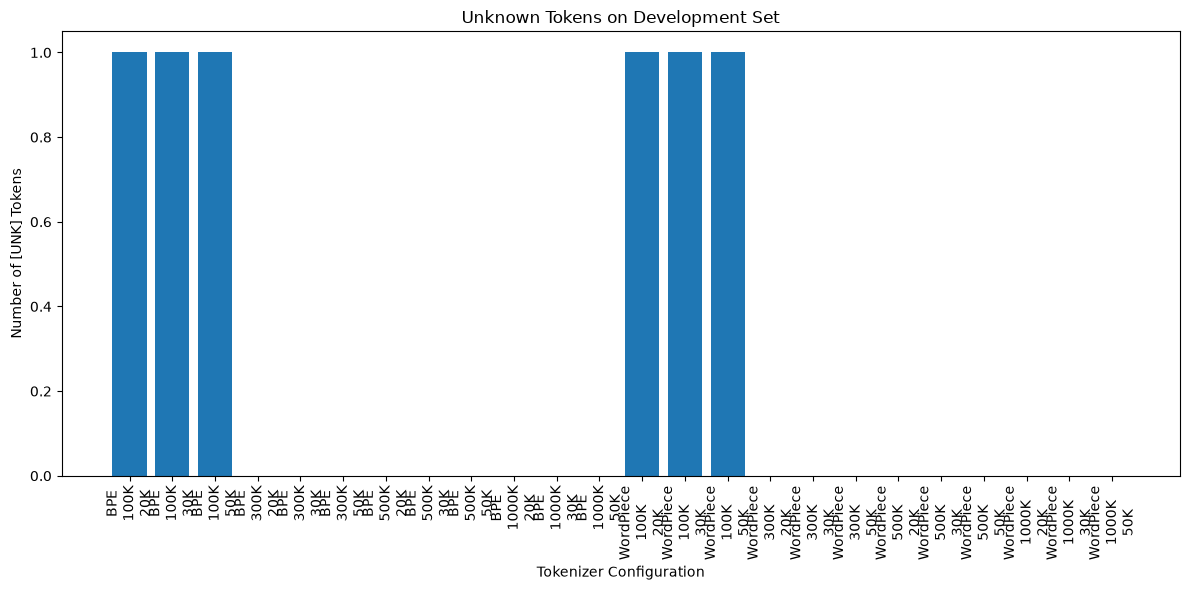

In [113]:
plt.figure(figsize=(12, 6))

unk_table = dev_results.copy()

labels = (
    unk_table["Algorithm"]
    + "\n"
    + (unk_table["Training Size"] // 1000).astype(str)
    + "K"
    + "\n"
    + (unk_table["Vocabulary Size"] // 1000).astype(str)
    + "K"
)

plt.bar(
    range(len(unk_table)),
    unk_table["UNK Tokens"]
)

plt.xticks(
    range(len(unk_table)),
    labels,
    rotation=90
)

plt.xlabel("Tokenizer Configuration")
plt.ylabel("Number of [UNK] Tokens")

plt.title(
    "Unknown Tokens on Development Set"
)

plt.tight_layout()
plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

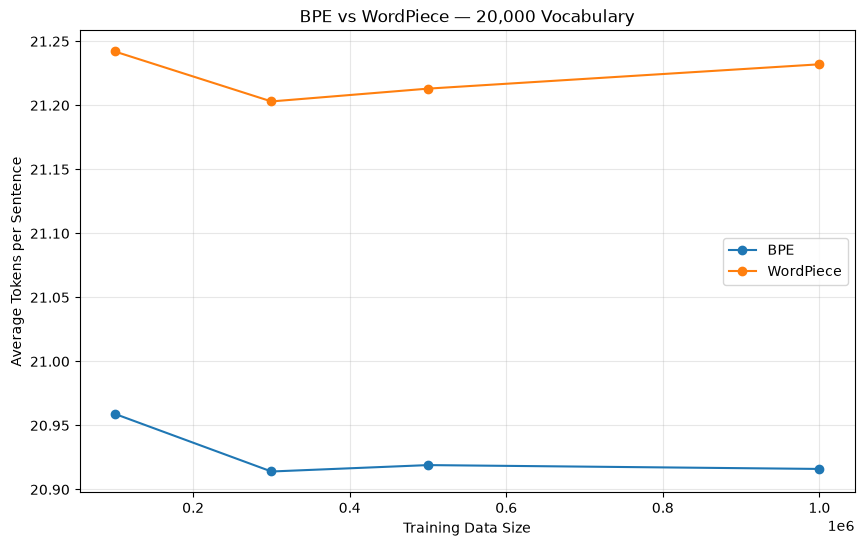

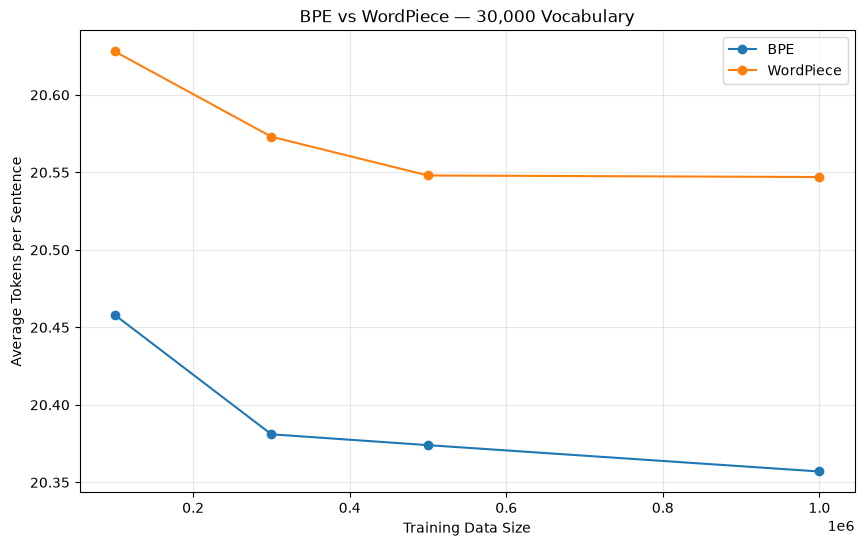

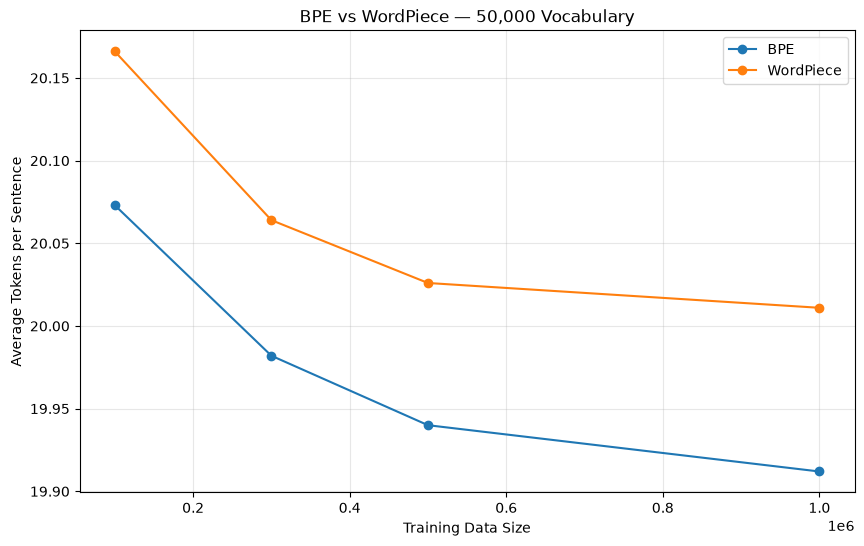

In [101]:
for vocab_size in VOCAB_SIZES:
    
    plt.figure(figsize=(10, 6))
    
    for algorithm in ["BPE", "WordPiece"]:
        
        subset = dev_results[
            (dev_results["Algorithm"] == algorithm) &
            (dev_results["Vocabulary Size"] == vocab_size)
        ].sort_values("Training Size")
        
        plt.plot(
            subset["Training Size"],
            subset["Average Tokens/Sentence"],
            marker="o",
            label=algorithm
        )
    
    plt.xlabel("Training Data Size")
    plt.ylabel("Average Tokens per Sentence")
    
    plt.title(
        f"BPE vs WordPiece — {vocab_size:,} Vocabulary"
    )
    
    plt.legend()
    plt.grid(alpha=0.3)
    
    plt.show()

### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

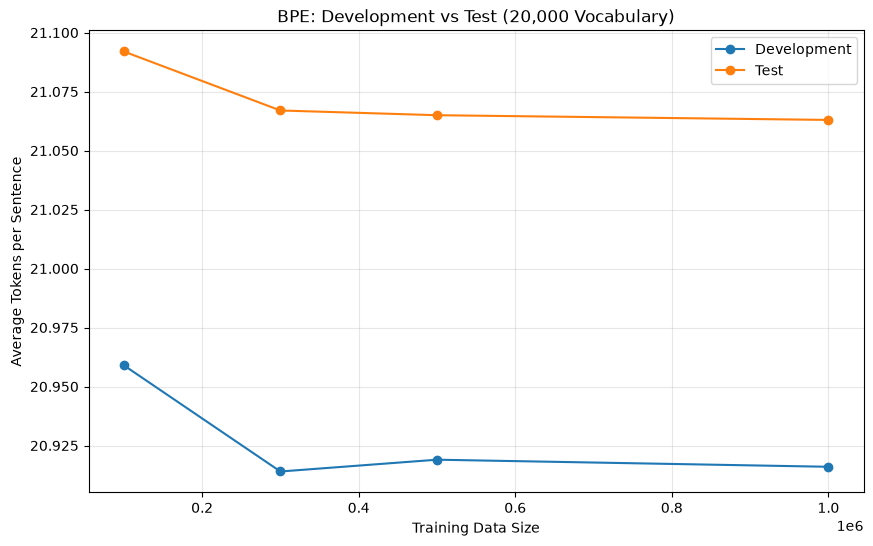

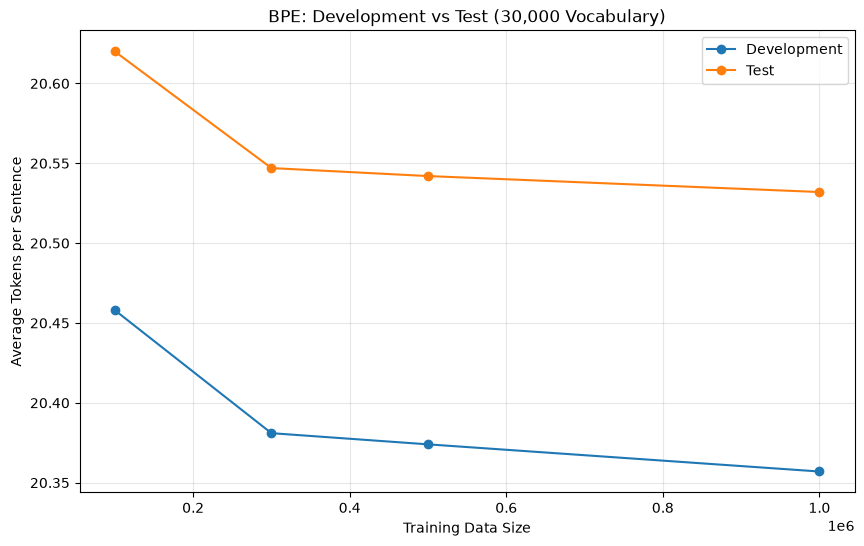

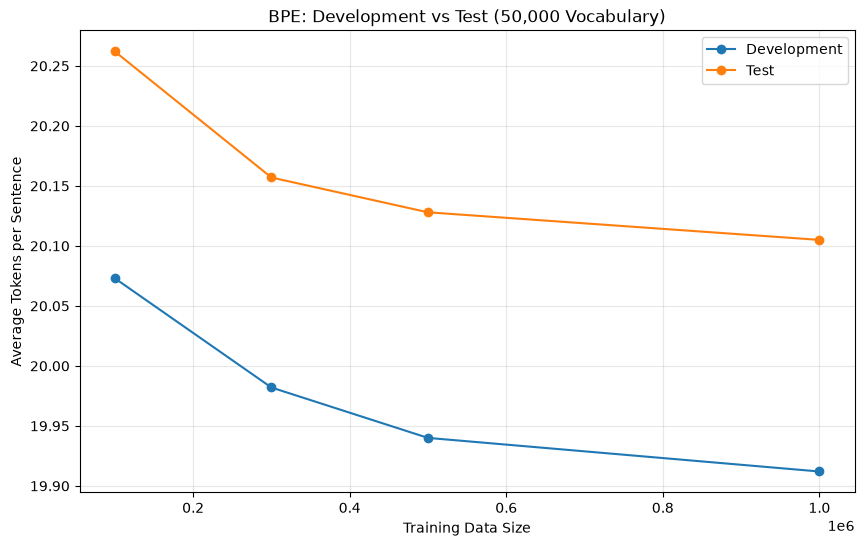

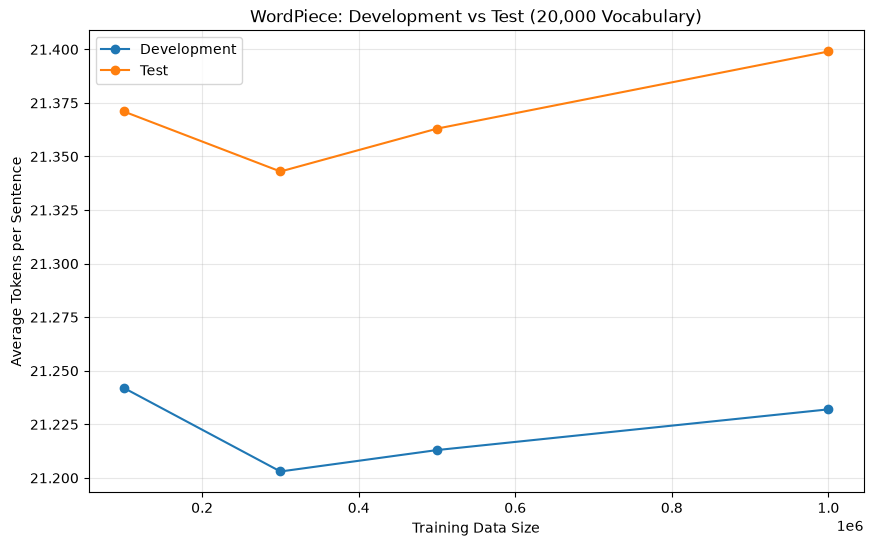

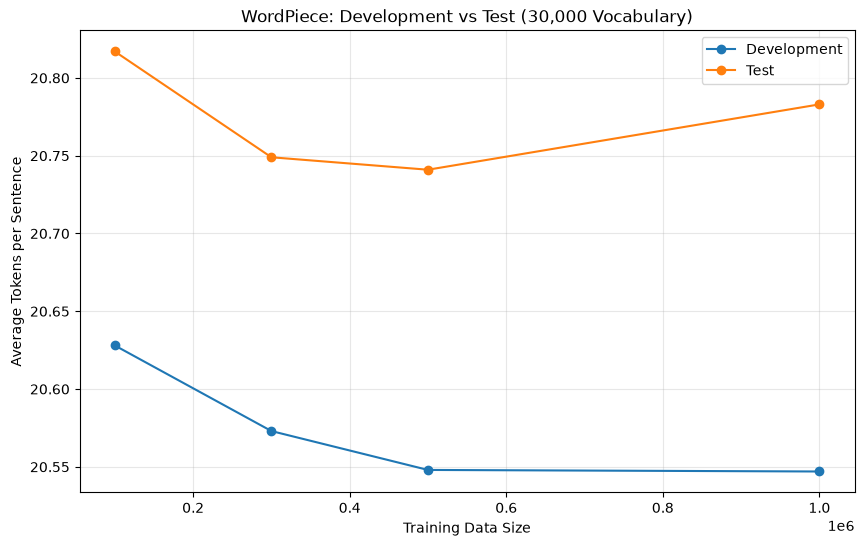

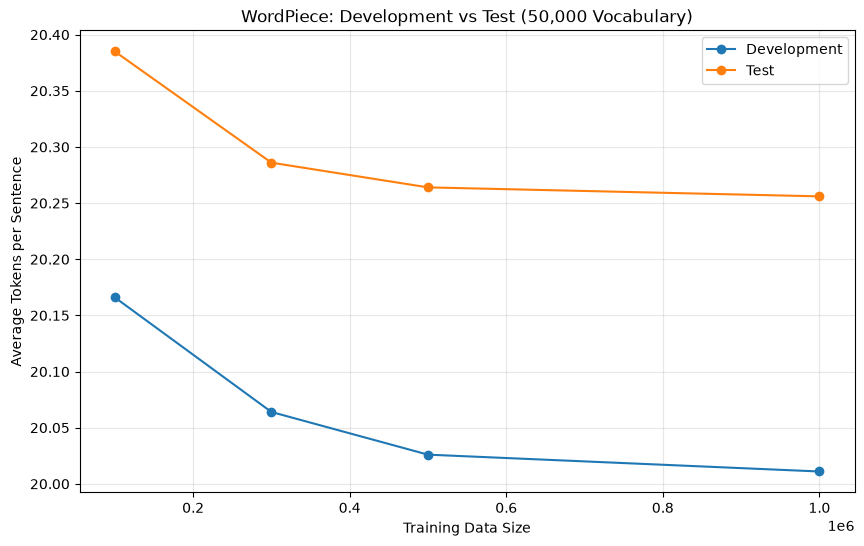

In [104]:
for algorithm in ["BPE", "WordPiece"]:
    
    for vocab_size in VOCAB_SIZES:
        
        plt.figure(figsize=(10, 6))
        
        for dataset_name in ["Development", "Test"]:
            
            subset = all_results[
                (all_results["Algorithm"] == algorithm) &
                (all_results["Vocabulary Size"] == vocab_size) &
                (all_results["Dataset"] == dataset_name)
            ].sort_values("Training Size")
            
            plt.plot(
                subset["Training Size"],
                subset["Average Tokens/Sentence"],
                marker="o",
                label=dataset_name
            )
        
        plt.xlabel("Training Data Size")
        plt.ylabel("Average Tokens per Sentence")
        
        plt.title(
            f"{algorithm}: Development vs Test "
            f"({vocab_size:,} Vocabulary)"
        )
        
        plt.legend()
        plt.grid(alpha=0.3)
        
        plt.show()

### Compare the 1M-token setting
This cell summarizes the strongest configurations at the largest training size.

In [105]:
comparison_1m = dev_results[
    dev_results["Training Size"] == 1_000_000
].copy()

comparison_1m = comparison_1m[
    [
        "Algorithm",
        "Vocabulary Size",
        "Total Tokens",
        "Average Tokens/Sentence",
        "Average Characters/Token",
        "UNK Tokens"
    ]
].sort_values(
    ["Vocabulary Size", "Algorithm"]
)

display(comparison_1m)

,Algorithm,Vocabulary Size,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens
18,BPE,20000,20916,20.916,4.226190,0
42,WordPiece,20000,21232,21.232,4.163291,0
20,BPE,30000,20357,20.357,4.342241,0
44,WordPiece,30000,20547,20.547,4.302088,0
22,BPE,50000,19912,19.912,4.439283,0
46,WordPiece,50000,20011,20.011,4.417320,0


### Compare the 1M-token setting
This cell summarizes the strongest configurations at the largest training size.

In [106]:
comparison_1m.to_csv(
    "comparison_1M_training.csv",
    index=False
)

### Measure compression efficiency
This chart compares how many characters each token contains across experiments.

In [107]:
bpe_training_effect = dev_results[
    dev_results["Algorithm"] == "BPE"
][
    [
        "Training Size",
        "Vocabulary Size",
        "Total Tokens",
        "Average Tokens/Sentence",
        "Average Characters/Token",
        "UNK Tokens"
    ]
].sort_values(
    ["Vocabulary Size", "Training Size"]
)

display(bpe_training_effect)

,Training Size,Vocabulary Size,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens
0,100000,20000,20959,20.959,4.217520,1
6,300000,20000,20914,20.914,4.226595,0
12,500000,20000,20919,20.919,4.225584,0
18,1000000,20000,20916,20.916,4.226190,0
2,100000,30000,20458,20.458,4.320804,1
8,300000,30000,20381,20.381,4.337128,0
14,500000,30000,20374,20.374,4.338618,0
20,1000000,30000,20357,20.357,4.342241,0
4,100000,50000,20073,20.073,4.403677,1
10,300000,50000,19982,19.982,4.423731,0


### Measure compression efficiency
This chart compares how many characters each token contains across experiments.

In [108]:
main_results = all_results[
    all_results["Training Size"] == 1_000_000
][
    [
        "Algorithm",
        "Vocabulary Size",
        "Dataset",
        "Total Tokens",
        "Average Tokens/Sentence",
        "Average Characters/Token",
        "UNK Tokens"
    ]
].sort_values(
    ["Algorithm", "Vocabulary Size", "Dataset"]
)

display(main_results)

,Algorithm,Vocabulary Size,Dataset,Total Tokens,Average Tokens/Sentence,Average Characters/Token,UNK Tokens
18,BPE,20000,Development,20916,20.916,4.226190,0
19,BPE,20000,Test,21063,21.063,4.192328,0
20,BPE,30000,Development,20357,20.357,4.342241,0
21,BPE,30000,Test,20532,20.532,4.300750,0
22,BPE,50000,Development,19912,19.912,4.439283,0
23,BPE,50000,Test,20105,20.105,4.392092,0
42,WordPiece,20000,Development,21232,21.232,4.163291,0
43,WordPiece,20000,Test,21399,21.399,4.126501,0
44,WordPiece,30000,Development,20547,20.547,4.302088,0
45,WordPiece,30000,Test,20783,20.783,4.248809,0


### Visualize BPE heatmap
This heatmap summarizes the average tokens per sentence across training and vocabulary sizes.

In [109]:
bpe_heatmap = dev_results[
    dev_results["Algorithm"] == "BPE"
].pivot(
    index="Training Size",
    columns="Vocabulary Size",
    values="Average Tokens/Sentence"
)

display(bpe_heatmap)

Vocabulary Size,20000,30000,50000
Training Size,,,
100000,20.959,20.458,20.073
300000,20.914,20.381,19.982
500000,20.919,20.374,19.940
1000000,20.916,20.357,19.912


### Visualize sentence lengths
This plot shows the distribution of sentence lengths so the data split can be chosen sensibly.

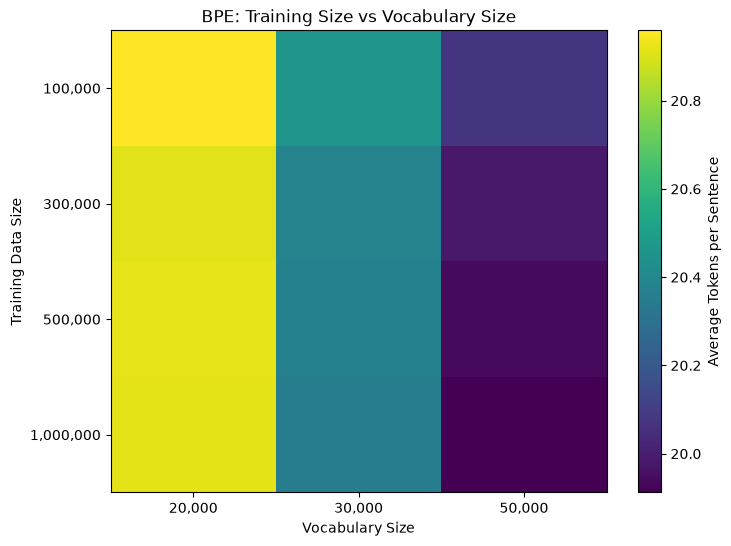

In [110]:
plt.figure(figsize=(8, 6))

plt.imshow(
    bpe_heatmap.values,
    aspect="auto"
)

plt.colorbar(
    label="Average Tokens per Sentence"
)

plt.xticks(
    range(len(bpe_heatmap.columns)),
    [f"{x:,}" for x in bpe_heatmap.columns]
)

plt.yticks(
    range(len(bpe_heatmap.index)),
    [f"{x:,}" for x in bpe_heatmap.index]
)

plt.xlabel("Vocabulary Size")
plt.ylabel("Training Data Size")

plt.title(
    "BPE: Training Size vs Vocabulary Size"
)

plt.show()

### Define the experiment grid
This block sets the training sizes and vocabulary sizes to compare tokenizer behavior across multiple conditions.

In [111]:
reduction_rows = []

for algorithm in ["BPE", "WordPiece"]:
    
    for training_size in TRAINING_SIZES:
        
        subset = dev_results[
            (dev_results["Algorithm"] == algorithm) &
            (dev_results["Training Size"] == training_size)
        ]
        
        tokens_20k = subset[
            subset["Vocabulary Size"] == 20_000
        ]["Average Tokens/Sentence"].iloc[0]
        
        for vocab_size in [30_000, 50_000]:
            
            tokens_current = subset[
                subset["Vocabulary Size"] == vocab_size
            ]["Average Tokens/Sentence"].iloc[0]
            
            reduction = (
                (tokens_20k - tokens_current)
                / tokens_20k
                * 100
            )
            
            reduction_rows.append({
                "Algorithm": algorithm,
                "Training Size": training_size,
                "Vocabulary Size": vocab_size,
                "Token Reduction (%)": reduction
            })

token_reduction = pd.DataFrame(
    reduction_rows
)

display(token_reduction)

,Algorithm,Training Size,Vocabulary Size,Token Reduction (%)
0,BPE,100000,30000,2.390381
1,BPE,100000,50000,4.227301
2,BPE,300000,30000,2.548532
3,BPE,300000,50000,4.456345
4,BPE,500000,30000,2.605287
5,BPE,500000,50000,4.679956
6,BPE,1000000,30000,2.672595
7,BPE,1000000,50000,4.800153
8,WordPiece,100000,30000,2.890500
9,WordPiece,100000,50000,5.065436
